> **Revisão documental — 20/10/2026:** Saídas históricas preservadas. C19: a contagem de tokens ainda traz o rótulo histórico “teste”, hoje identificado como validação. C24/C25/C27: há resultados GloVe salvos de um ramo atualmente desativado por EXPLORAR_GLOVE=False. C24: há logs de montagem do Drive que a preparação atual não executa. C32: os rótulos “Teste” salvos precedem a identificação atual do conjunto como validação. Execução integral desta revisão no Colab pendente.

# Classificação com CNN/LSTM e embedding treinável

O modelo ativo combina CNN e LSTM com embedding treinável de 128 dimensões. A alternativa comentada com GloVe não participa da execução.

## Preparação da sessão e dos insumos

Execute a célula abaixo antes das atividades. Ela encontra o repositório na sessão local; no Colab, cria uma cópia em `/content/pos-graduacao-ia-ciencia-dados` apenas se essa pasta ainda não existir, sem alterar o diretório de trabalho. Um clone existente precisa ser atualizado por você quando necessário. Mudanças locais só ficam disponíveis nessa cópia do Colab após serem publicadas no remoto.

A exploração GloVe fica desativada por padrão (`EXPLORAR_GLOVE = False`) na preparação abaixo; o classificador pode ser executado sem esse arquivo. Para explorar os vetores, baixe e extraia o conjunto oficial conforme [as instruções do GloVe](../../dados/glove/README.md), copie `glove.6B.50d.txt` para `disciplinas/processamento-linguagem-natural/dados/glove/` no repositório da sessão e altere o controle para `True`. Execute novamente a preparação e, depois, as células exploratórias na ordem apresentada. A preparação informa o destino absoluto caso falte o arquivo solicitado.

As saídas salvas foram preservadas como registros históricos; podem incluir a exploração GloVe realizada anteriormente. A preparação dos caminhos não valida a execução integral nem a compatibilidade das demais dependências.

## Alcance da avaliação

Este exemplo usa uma divisão didática em treino e validação. Os nomes `X_test`, `y_test`, `tk_pad_X_test` e `ohe_y_test` foram mantidos no código, mas identificam o conjunto usado em `validation_data` para monitoramento a cada época. Cada chamada posterior a `evaluate` reutiliza esses mesmos dados; sua acurácia descreve o conjunto usado para validação. Não há uma reserva de teste independente para avaliar escolhas baseadas nesse monitoramento ou na comparação das variantes.

As saídas salvas são históricas: rótulos antigos como “Acurácia do Teste” não demonstram avaliação independente e não representam uma nova execução das fontes corrigidas.

In [ ]:
from pathlib import Path
import subprocess

SLUG = "processamento-linguagem-natural"
_session_dir = Path.cwd().resolve()
REPO_DIR = next(
    (p for p in (_session_dir, *_session_dir.parents)
     if (p / "disciplinas" / SLUG).is_dir()),
    None,
)
if REPO_DIR is None:
    if not Path("/content").is_dir():
        raise FileNotFoundError("Abra a sessão na raiz do repositório ou em uma de suas subpastas.")
    REPO_DIR = Path("/content/pos-graduacao-ia-ciencia-dados")
    if not REPO_DIR.exists():
        subprocess.run([
            "git", "clone", "--depth", "1",
            "https://github.com/wellingtonmnf/pos-graduacao-ia-ciencia-dados.git",
            str(REPO_DIR),
        ], check=True)

DISCIPLINA_DIR = REPO_DIR / "disciplinas" / SLUG
DATA_DIR = DISCIPLINA_DIR / "dados"
if not DISCIPLINA_DIR.is_dir() or not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Estrutura de dados ausente em {DISCIPLINA_DIR}. Atualize o clone para a revisão que contém dados/."
    )

EXPLORAR_GLOVE = False  # True habilita somente a exploração dos vetores.
embedding_matrix = None  # Limpa eventual matriz de uma execução anterior.
GLOVE_PATH = DATA_DIR / "glove" / "glove.6B.50d.txt"
if EXPLORAR_GLOVE and not GLOVE_PATH.is_file():
    raise FileNotFoundError(
        f"Obtenha manualmente glove.6B.50d.txt e copie para {GLOVE_PATH}. "
        f"Consulte {DATA_DIR / 'glove' / 'README.md'}. Depois, execute esta célula novamente."
    )

In [1]:
# Preparação da dependência usada pelo adaptador Pandas.
%pip install "kagglehub[pandas-datasets]"
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Defina o nome do arquivo correto do dataset
file_path = "IMDB Dataset.csv"

# Carrega a versão 1, comparada em 2026-10-19, preservando a ordem das resenhas.
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1",
  file_path
)

if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("Colunas inesperadas no IMDb")
if df["review"].isna().any() or not df["review"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
    raise ValueError("Resenhas ausentes ou inválidas")
if df["sentiment"].isna().any() or not df["sentiment"].isin(["positive", "negative"]).all():
    raise ValueError("Rótulos inesperados no IMDb")

print("Primeiros 5 registros:")
display(df.head())

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Primeiros 5 registros:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
df.isnull().sum()

,0
review,0
sentiment,0


In [3]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


<Axes: title={'center': 'Quantidade por Tipo'}, xlabel='sentiment'>

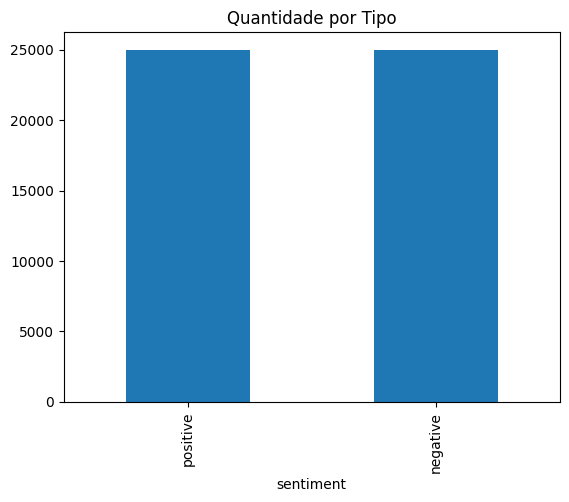

In [4]:
df["sentiment"].value_counts().plot.bar(title='Quantidade por Tipo',rot=90)

In [5]:
!pip install nltk
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [6]:
exemplo = df['review'].values[0]
print(exemplo)
print(len(exemplo.split()))

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [7]:
%%time
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
TAMANHO_MIMINO = 1
IGNORAR = ['...', 'br','.so','\'ll']
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    palavras = [i for i in palavras if len(i) > TAMANHO_MIMINO]
    palavras = [i.lower() for i in palavras if i not in IGNORAR]
    return palavras

CPU times: user 2.42 ms, sys: 6 µs, total: 2.42 ms
Wall time: 2.18 ms


In [8]:
%%time
df['review2'] = df['review'].apply(prepara)
df['review2'] = df['review2'].apply(' '.join)

CPU times: user 1min 49s, sys: 464 ms, total: 1min 50s
Wall time: 2min 1s


In [9]:
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one reviewers mentioned watching oz episode ho...
1,A wonderful little production. <br /><br />The...,positive,wonderful little production the filming techni...
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,basically 's family little boy jake thinks 's ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visuall...


In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['review2'], df['sentiment'], test_size=0.2, random_state=0)
print('X_train shape:',X_train.shape)
print('y_train shape:',y_train.shape)
print('X_test shape:',X_test.shape)
print('y_test shape:',y_test.shape)

X_train shape: (40000,)
y_train shape: (40000,)
X_test shape: (10000,)
y_test shape: (10000,)


In [11]:
%%time
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=10000)

CPU times: user 4.53 s, sys: 481 ms, total: 5.02 s
Wall time: 8.19 s


In [12]:
# fit_on_texts varre todo o X_train e constrói o word_index completo,
# independente do limite de num_words — a restrição só vale na conversão.
tokenizer.fit_on_texts(X_train)

In [13]:
tk_X_train = tokenizer.texts_to_sequences(X_train)
tk_X_test  = tokenizer.texts_to_sequences(X_test)

In [14]:
# O +1 reserva o índice 0 para o padding, que será usado em etapas futuras.
vocab_size = len(tokenizer.word_index) + 1

In [15]:
# X_train é uma Series do pandas com índices embaralhados pelo train_test_split.
# X_train[0] busca pelo RÓTULO 0, que pode não existir ou apontar para
# uma review diferente da posição 0 da sequência numérica.
# A solução é usar .iloc[0], que acessa sempre pela POSIÇÃO real.
print("Texto original:     ", X_train.iloc[0])
print("Sequência numérica: ", tk_X_train[0])

Texto original:      that 's redeeming quality movie otherwise insults viewer 's intelligence losing track time plot reason produced. plus guy glasses ever got gig hollywood beyond
Sequência numérica:  [138, 1, 1656, 396, 3, 797, 7202, 425, 1, 1663, 2304, 1306, 14, 46, 202, 931, 836, 123, 4337, 52, 97, 8069, 267, 585]


In [16]:
# Verificação de sanidade: confirma que texto e sequência correspondem
# Útil para rodar sempre que você modificar o pipeline de dados
print("\n--- Verificação de sanidade ---")
print("Índices reais do X_train:", X_train.index[:5].tolist())
print("Primeiras palavras: ", X_train.iloc[0][:60])
print("Primeiros 10 tokens:", tk_X_train[0][:10])


--- Verificação de sanidade ---
Índices reais do X_train: [20330, 17532, 45819, 34807, 31888]
Primeiras palavras:  that 's redeeming quality movie otherwise insults viewer 's 
Primeiros 10 tokens: [138, 1, 1656, 396, 3, 797, 7202, 425, 1, 1663]


In [17]:
total_tokens_train = sum(len(seq) for seq in tk_X_train)
total_tokens_test = sum(len(seq) for seq in tk_X_test)

print(f'Total de tokens nos dados de treino: {total_tokens_train}')
print(f'Total de tokens nos dados de validação: {total_tokens_test}')

Total de tokens nos dados de treino: 4835304
Total de tokens nos dados de teste: 1216659


In [18]:
print('vocab_size:',vocab_size)

vocab_size: 98250


In [19]:
print('Max size:',max([len(i) for i in tk_X_train]))

Max size: 1170


In [20]:
%%time
from keras.utils import pad_sequences
max_len = 200
tk_pad_X_train = pad_sequences(tk_X_train, padding='post', maxlen=max_len)
tk_pad_X_test = pad_sequences(tk_X_test, padding='post', maxlen=max_len)

CPU times: user 519 ms, sys: 16 ms, total: 535 ms
Wall time: 537 ms


In [21]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
ohe_y_train = lb.fit_transform(y_train)
ohe_y_test = lb.transform(y_test)
print('ohe_y_train shape:',ohe_y_train.shape)
print('ohe_y_test shape:',ohe_y_test.shape)

ohe_y_train shape: (40000, 1)
ohe_y_test shape: (10000, 1)


In [23]:
# GloVe localizado pela célula de preparação.
if EXPLORAR_GLOVE:
    with GLOVE_PATH.open("r", encoding="utf-8") as f:
        print(f.readline(100).rstrip())

Mounted at /content/drive
Arquivo lido com sucesso!
Prévia do conteúdo: the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.044457 -0.49688 -0.17862 -0.00066023 -0.6566 0.27843 -0...


In [24]:
if EXPLORAR_GLOVE:
    with GLOVE_PATH.open("r", encoding="utf-8") as f:
        print(f.readline(100).rstrip())

the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.044457 -0.49688 -0.17862 -0.00066023 -0.6566 0.27843 -0


In [25]:
%%time
import numpy as np
def create_embedding(path, word_index, embedding_dim):
    vocab_size = len(word_index) + 1
    embedding = np.zeros((vocab_size, embedding_dim))
    with open(path) as f:
        for line in f:
            w, *vector = line.split()
            if w in word_index:
                idx = word_index[w]
                embedding[idx] = np.array(vector, dtype=np.float32)[:embedding_dim]
    return embedding

CPU times: user 7 µs, sys: 0 ns, total: 7 µs
Wall time: 10.5 µs


In [26]:
%%time
embedding_dim = 50
embedding_matrix = None  # Limpa eventual matriz de uma execução anterior.
if EXPLORAR_GLOVE:
    embedding_matrix = create_embedding(GLOVE_PATH, tokenizer.word_index, embedding_dim)
    print(embedding_matrix.shape)

(98250, 50)
CPU times: user 3.29 s, sys: 216 ms, total: 3.5 s
Wall time: 3.7 s


In [27]:
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, Dropout, LSTM, Conv1D, MaxPooling1D
from keras.optimizers import Adam, Nadam

In [28]:
NB_EPOCH = 3
BATCH_SIZE = 256
VERBOSE = 1
OPTIMIZER = Adam()

In [29]:
from keras import Input

model = Sequential()
model.add(Input(shape=(max_len,), dtype="int32"))
#model.add(Embedding(input_dim=vocab_size, output_dim=50, weights=[embedding_matrix], trainable=False))
model.add(Embedding(vocab_size, 128))
model.add(Conv1D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling1D(pool_size=2))
model.add(LSTM(128))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [30]:
%%time
# O conjunto de validação monitorado aqui é reutilizado na avaliação abaixo.
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 158s 975ms/step - accuracy: 0.5807 - loss: 0.6519 - val_accuracy: 0.8154 - val_loss: 0.4613
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 146s 928ms/step - accuracy: 0.8819 - loss: 0.3019 - val_accuracy: 0.8882 - val_loss: 0.2904
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 215s 1s/step - accuracy: 0.9271 - loss: 0.2112 - val_accuracy: 0.8904 - val_loss: 0.2795
CPU times: user 10min 25s, sys: 1min 10s, total: 11min 35s
Wall time: 8min 38s


In [31]:
# Avaliação nos mesmos dados usados para validação durante o treino.
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia no conjunto usado para validação:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.8904


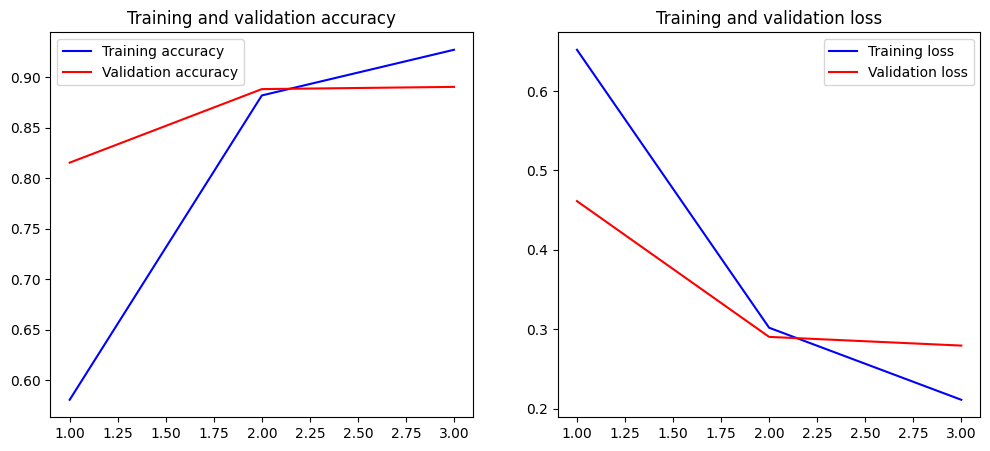

In [33]:
import matplotlib.pyplot as plt
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training accuracy')
    plt.plot(x, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
plot_history(history)